In [1]:
import numpy as np

import jax.numpy as jnp
from jax import jit, vmap, grad
import jax.random

import scipy.optimize
import matplotlib.pyplot as plt

import emcee
import corner
# import tensorflow_probability.substrates.jax as tfp
from bayesian_stats_course_tools.plotting import plot_contours

import numpyro.distributions as dist
import numpyro
from numpyro import infer

# Exercise 1

For the linear model $y_i \sim N(mx_i + b, \sigma_i)$ and data from `../lectures/data/linear_fits/data_0.txt` do the following:

1. Analytically calculate the FIM using either the Hessian definition or the grad definition.

__Solution__: $$\mathcal  I= \begin{pmatrix} \sum_{i} \frac{x_{i}^{2}}{\sigma_{i}^{2}} & \sum_{i} \frac{x_{i}}{\sigma_{i}^{2}}  \\ \sum_{i} \frac{x_{i}}{\sigma_{i}^{2}} & \sum_{i} \frac{1}{\sigma_{i}^{2}} \end{pmatrix}$$

2. Write a function that calculates this based on the $x$-values and $\sigma$.

In [6]:
x, y, y_err = np.loadtxt('../lectures/data/linear_fits/data_0.txt', unpack=True)

I_mm = np.sum( x**2 / y_err ** 2)
I_bb = np.sum(1/y_err **2)
I_mb = np.sum(x/y_err**2)

print(f'{I_mm=:.2f}')
print(f'{I_bb=:.2f}')
print(f'{I_mb=:.2f}')

I_mm=334.28
I_bb=222.22
I_mb=233.06


3. Implement the likelihood in JAX and use `jax.hessian` or `jax.grad` to calculate the FIM and compare to (2). If you use `jax.hessian`, check that properties of the analytic FIM propagate here (e.g. whether it is independent of certain variables).

In [42]:
def model(x, m, b):
    return m * x + b

def likelihood(x, y, y_err, m, b):
    return np.prod(
        1/np.sqrt(2 * np.pi * y_err) * np.exp( -.5 * (y - (m * x + b ))**2 /y_err ** 2)
    )

@jax.jit
def log_likelihood(x, y, y_err, m, b):
    return jnp.sum(
        -.5 * (y- (m * x + b)) ** 2 /y_err ** 2
    ) - .5 * np.sum( jnp.log(2 * jnp.pi * y_err**2) )


In [32]:
theta_HAT = scipy.optimize.minimize(
    fun=lambda theta: -log_likelihood(x, y, y_err, theta[0], theta[1]),
    jac=jax.grad(lambda theta: -log_likelihood(x,y,y_err, theta[0], theta[1])),
    method='L-BFGS-B',
    x0=[0., 0.]
).x

In [33]:
print(theta_HAT)

[ 1.25482361 -0.14972449]


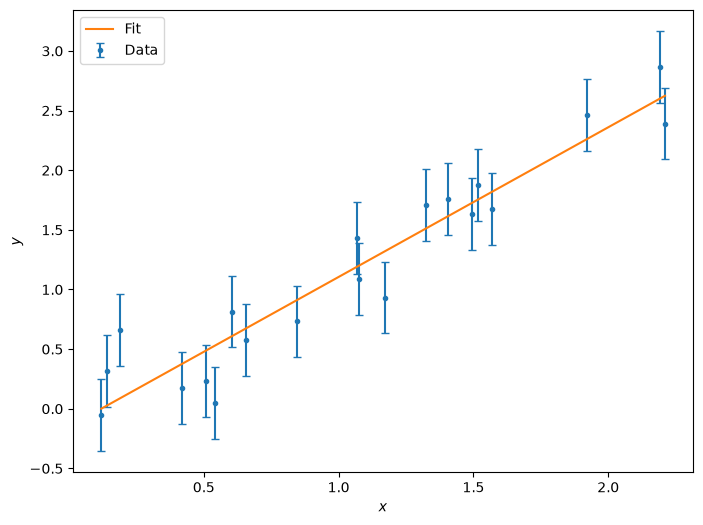

In [45]:
fig, ax = plt.subplots(figsize=(8,6))

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.errorbar(x, y, yerr=y_err, fmt=' ', capsize=3, marker='.', label='Data')

ax.plot(x, model(x, *theta_HAT), label='Fit')

ax.legend()


In [49]:
hess = jax.hessian(log_likelihood, argnums=[3,4])
FIM = -1 * hess(x, y, y_err, *theta_HAT)

In [50]:
print(FIM)

()


# Exercise 2: Hierarchical models and probabilistic programming

We have test scores $y_{ij}$ for schools across several cities, where $j$ labels the city and $i$ labels the school within that city.
Schools in the same city share a mean test score $\theta_j$, and the city means are themselves drawn from a country-wide Gaussian:

$y_{ij} \sim \mathcal N_y(\theta_j, \sigma_{ij}^2)$
$\theta_j \sim \mathcal N_\theta(\mu, \tau^2)$
$\mu \sim \mathcal U(0, 100)$
$\log_{10} \tau \sim \mathcal U(-2, 2)$

where we have used a Jeffreys prior on $\tau$.

The data are in `lectures/data/fake_school_data.txt`: 20 cities with 10 schools each.
The file has 40 columns that alternate between the scores of the schools in a city and the variances $\sigma_{ij}^2$ of those scores
(column 1: scores in city 1, column 2: variances in city 1, column 3: scores in city 2, ...).

1. Implement this model in `numpyro`.
2. Sample the posterior of $\mu$, $\tau$ and the $\theta_j$ with NUTS.
3. Compare the posterior means of the $\theta_j$ with the per-city average scores. What does the hierarchical model do to them?

In [3]:
# Notation:
#   n_city             number of cities (groups), here 20
#   n_school_per_city  number of schools per city, here 10
school_table = np.loadtxt("../lectures/data/fake_school_data.txt")  # (n_school_per_city, 2 * n_city)

# Columns alternate (scores, variances) per city; transpose so cities are rows
scores = school_table[:, 0::2].T           # (n_city, n_school_per_city)
score_variances = school_table[:, 1::2].T  # (n_city, n_school_per_city)
score_sigmas = np.sqrt(score_variances)    # (n_city, n_school_per_city)

n_city, n_school_per_city = scores.shape
print(f"{n_city} cities with {n_school_per_city} schools each")

num_samples=10_000

20 cities with 10 schools each
